In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
wine = load_wine()

X = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)

y = wine.target

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
print("First five rows:")
display(X.head())

print("Dataset shape:", X.shape)
print("Number of features:", X.shape[1])
print("Number of samples:", X.shape[0])

print("\nClass names:")
print(wine.target_names)

First five rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


Dataset shape: (178, 13)
Number of features: 13
Number of samples: 178

Class names:
['class_0' 'class_1' 'class_2']


In [4]:
print("Missing values in each feature:")
print(X.isnull().sum())

print("\nTotal missing values:", X.isnull().sum().sum())

Missing values in each feature:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64

Total missing values: 0


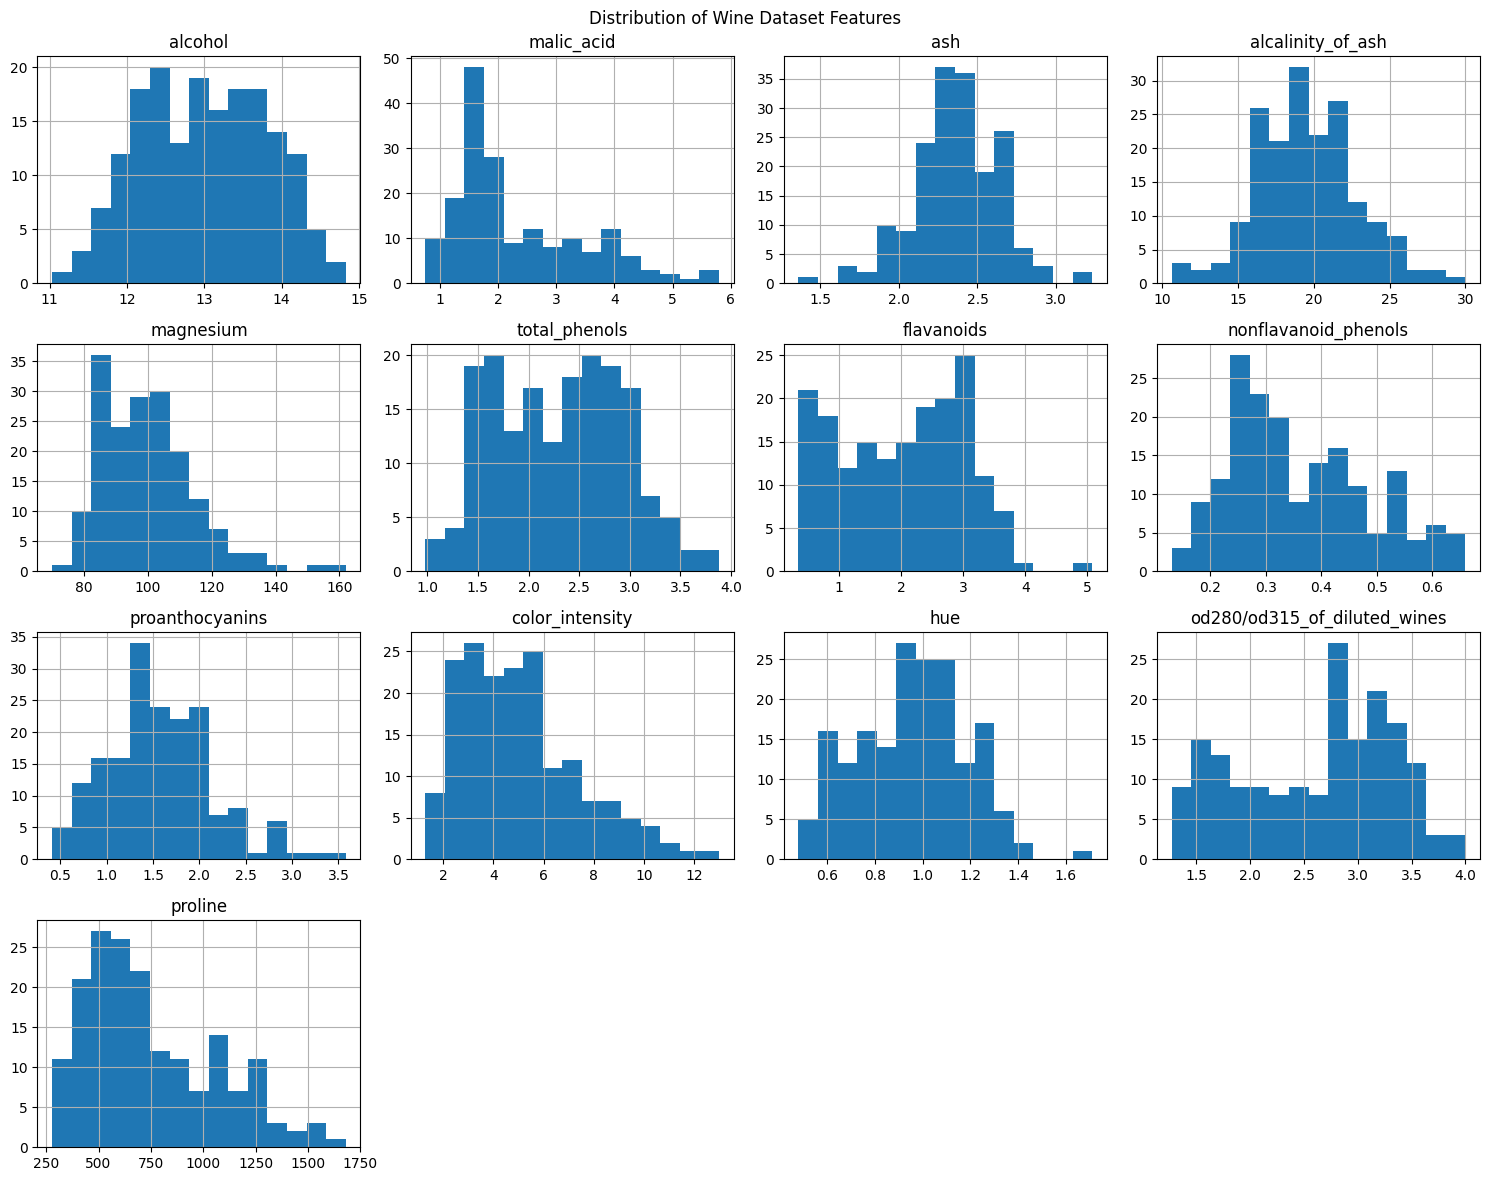

In [5]:
X.hist(figsize=(15, 12), bins=15)

plt.suptitle("Distribution of Wine Dataset Features")
plt.tight_layout()
plt.show()

In [6]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Original shape:", X.shape)
print("Standardized shape:", X_scaled.shape)

print("\nMean of first three standardized features:")
print(X_scaled.mean(axis=0)[:3])

print("\nStandard deviation of first three features:")
print(X_scaled.std(axis=0)[:3])

Original shape: (178, 13)
Standardized shape: (178, 13)

Mean of first three standardized features:
[-8.38280756e-16 -1.19754394e-16 -8.37033314e-16]

Standard deviation of first three features:
[1. 1. 1.]


In [7]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original number of features:", X.shape[1])
print("Reduced number of features:", X_pca.shape[1])
print("Reduced dataset shape:", X_pca.shape)

Original number of features: 13
Reduced number of features: 2
Reduced dataset shape: (178, 2)


In [8]:
explained_variance = pca.explained_variance_ratio_

print("PC1 explained variance:",
      explained_variance[0] * 100, "%")

print("PC2 explained variance:",
      explained_variance[1] * 100, "%")

print("Total variance retained:",
      explained_variance.sum() * 100, "%")

PC1 explained variance: 36.19884809992633 %
PC2 explained variance: 19.207490257008946 %
Total variance retained: 55.40633835693527 %


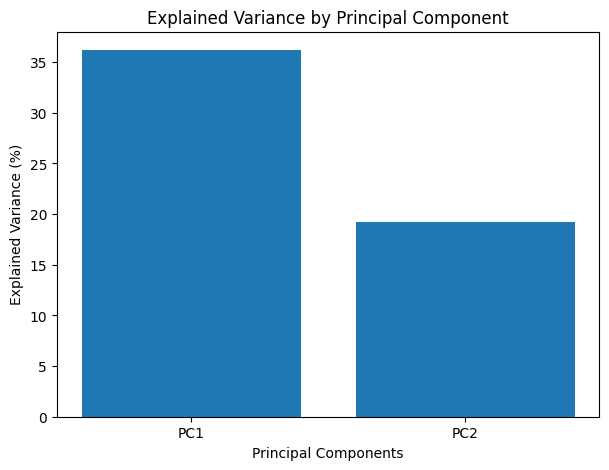

In [9]:
plt.figure(figsize=(7, 5))

components = ["PC1", "PC2"]

plt.bar(components, explained_variance * 100)

plt.ylabel("Explained Variance (%)")
plt.xlabel("Principal Components")
plt.title("Explained Variance by Principal Component")

plt.show()

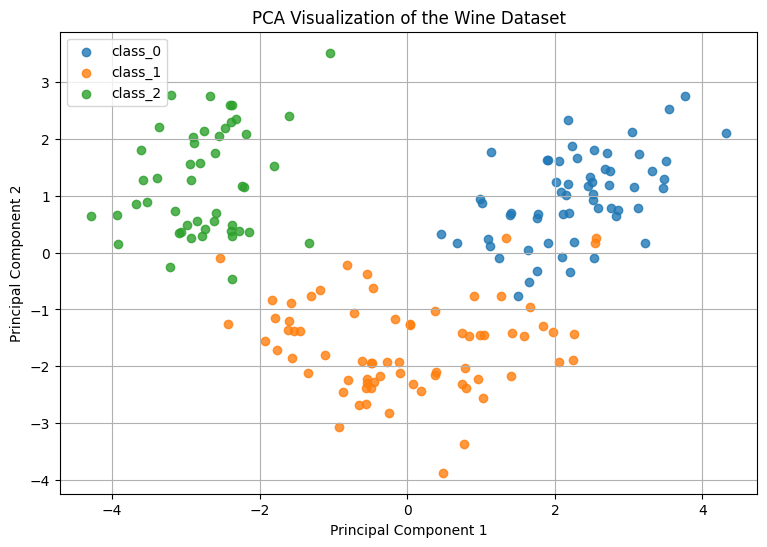

In [11]:
plt.figure(figsize=(9, 6))

for i, name in enumerate(wine.target_names):
    plt.scatter(
        X_pca[y == i, 0],
        X_pca[y == i, 1],
        label=name,
        alpha=0.8
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of the Wine Dataset")

plt.legend()
plt.grid(True)
plt.show()

In [12]:
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

pca_df["Wine_Class"] = [
    wine.target_names[i] for i in y
]

display(pca_df.head())

,PC1,PC2,Wine_Class
0,3.316751,1.443463,class_0
1,2.209465,-0.333393,class_0
2,2.516740,1.031151,class_0
3,3.757066,2.756372,class_0
4,1.008908,0.869831,class_0


In [13]:
print("========== PCA SUMMARY ==========")

print(f"Original features: {X.shape[1]}")
print(f"Reduced features: {X_pca.shape[1]}")

print(
    f"Dimensionality reduction: "
    f"{(1 - X_pca.shape[1] / X.shape[1]) * 100:.2f}%"
)

print(
    f"Total variance retained: "
    f"{pca.explained_variance_ratio_.sum() * 100:.2f}%"
)

========== PCA SUMMARY ==========
Original features: 13
Reduced features: 2
Dimensionality reduction: 84.62%
Total variance retained: 55.41%
